# Prog08: Learning Vector Quantization (LVQ) for Classification


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split


# Generate sample classification data


In [4]:
# Generate 2D classification data with 3 classes
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, 
                          n_informative=2, n_clusters_per_class=1, 
                          n_classes=3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Training data shape: {X_train.shape}")
print(f"Test data shape: {X_test.shape}")
print(f"Classes: {np.unique(y)}")


Training data shape: (140, 2)
Test data shape: (60, 2)
Classes: [0 1 2]


# LVQ Implementation


In [5]:
class LVQ:
    def __init__(self, n_prototypes_per_class=2, learning_rate=0.1):
        self.n_prototypes_per_class = n_prototypes_per_class
        self.learning_rate = learning_rate
        self.prototypes = None
        self.prototype_labels = None
        
    def initialize_prototypes(self, X, y):
        """Initialize prototypes for each class"""
        classes = np.unique(y)
        n_features = X.shape[1]
        
        prototypes = []
        prototype_labels = []
        
        for class_label in classes:
            class_data = X[y == class_label]
            # Select random prototypes for this class
            indices = np.random.choice(len(class_data), 
                                     min(self.n_prototypes_per_class, len(class_data)), 
                                     replace=False)
            prototypes.extend(class_data[indices])
            prototype_labels.extend([class_label] * len(indices))
        
        self.prototypes = np.array(prototypes)
        self.prototype_labels = np.array(prototype_labels)
        
    def find_winner(self, x):
        """Find the closest prototype (winner)"""
        distances = np.sum((self.prototypes - x) ** 2, axis=1)
        winner_idx = np.argmin(distances)
        return winner_idx, distances[winner_idx]
    
    def train(self, X, y, epochs=100):
        """Train LVQ using LVQ1 algorithm"""
        self.initialize_prototypes(X, y)
        
        for epoch in range(epochs):
            # Decay learning rate
            current_lr = self.learning_rate * (1 - epoch / epochs)
            
            # Shuffle training data
            indices = np.random.permutation(len(X))
            
            for idx in indices:
                x = X[idx]
                true_label = y[idx]
                
                # Find winner
                winner_idx, _ = self.find_winner(x)
                winner_label = self.prototype_labels[winner_idx]
                
                # Update winner prototype
                if winner_label == true_label:
                    # Move prototype towards input
                    self.prototypes[winner_idx] += current_lr * (x - self.prototypes[winner_idx])
                else:
                    # Move prototype away from input
                    self.prototypes[winner_idx] -= current_lr * (x - self.prototypes[winner_idx])
    
    def predict(self, X):
        """Predict class labels for input data"""
        predictions = []
        for x in X:
            winner_idx, _ = self.find_winner(x)
            predictions.append(self.prototype_labels[winner_idx])
        return np.array(predictions)
    
    def get_accuracy(self, X, y):
        """Calculate accuracy"""
        predictions = self.predict(X)
        return np.mean(predictions == y)


# Train LVQ


In [6]:
# Create and train LVQ
lvq = LVQ(n_prototypes_per_class=3, learning_rate=0.1)
print("Training LVQ...")
lvq.train(X_train, y_train, epochs=100)
print("Training completed!")

# Evaluate performance
train_accuracy = lvq.get_accuracy(X_train, y_train)
test_accuracy = lvq.get_accuracy(X_test, y_test)

print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")


Training LVQ...
Training completed!
Training accuracy: 0.807
Test accuracy: 0.817


# Visualization


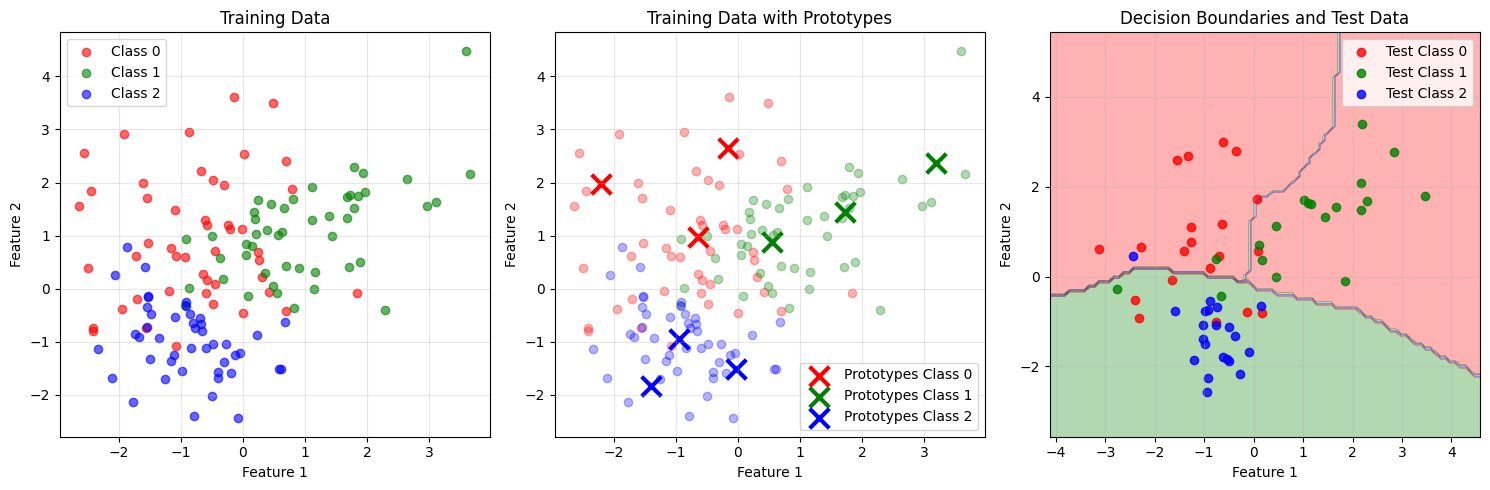

In [7]:
# Plot training data and prototypes
plt.figure(figsize=(15, 5))

# Plot training data
plt.subplot(1, 3, 1)
colors = ['red', 'green', 'blue']
for i, class_label in enumerate(np.unique(y_train)):
    mask = y_train == class_label
    plt.scatter(X_train[mask, 0], X_train[mask, 1], 
               c=colors[i], label=f'Class {class_label}', alpha=0.6)
plt.title('Training Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot prototypes
plt.subplot(1, 3, 2)
for i, class_label in enumerate(np.unique(y_train)):
    mask = y_train == class_label
    plt.scatter(X_train[mask, 0], X_train[mask, 1], 
               c=colors[i], alpha=0.3)
    
    # Plot prototypes for this class
    prototype_mask = lvq.prototype_labels == class_label
    plt.scatter(lvq.prototypes[prototype_mask, 0], 
               lvq.prototypes[prototype_mask, 1], 
               c=colors[i], s=200, marker='x', linewidth=3, 
               label=f'Prototypes Class {class_label}')

plt.title('Training Data with Prototypes')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot decision boundaries
plt.subplot(1, 3, 3)
# Create a mesh for decision boundary
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

# Predict for mesh points
mesh_points = np.c_[xx.ravel(), yy.ravel()]
Z = lvq.predict(mesh_points)
Z = Z.reshape(xx.shape)

# Plot decision regions
plt.contourf(xx, yy, Z, alpha=0.3, colors=colors)
for i, class_label in enumerate(np.unique(y_test)):
    mask = y_test == class_label
    plt.scatter(X_test[mask, 0], X_test[mask, 1], 
               c=colors[i], label=f'Test Class {class_label}', alpha=0.8)

plt.title('Decision Boundaries and Test Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Display prototype information


In [8]:
# Show prototype details
print("LVQ Prototypes:")
for i, (prototype, label) in enumerate(zip(lvq.prototypes, lvq.prototype_labels)):
    print(f"Prototype {i+1}: {prototype} -> Class {label}")

# Show some test predictions
print(f"\nTest Predictions (first 10):")
test_predictions = lvq.predict(X_test)
for i in range(min(10, len(X_test))):
    print(f"Input: {X_test[i]} -> Predicted: {test_predictions[i]}, Actual: {y_test[i]}")


LVQ Prototypes:
Prototype 1: [-0.65099783  0.9699116 ] -> Class 0
Prototype 2: [-0.16369039  2.65199151] -> Class 0
Prototype 3: [-2.20220502  1.96386254] -> Class 0
Prototype 4: [1.72360739 1.4480996 ] -> Class 1
Prototype 5: [3.19247534 2.37375465] -> Class 1
Prototype 6: [0.54845751 0.87256126] -> Class 1
Prototype 7: [-1.39818687 -1.84368433] -> Class 2
Prototype 8: [-0.02934252 -1.52322576] -> Class 2
Prototype 9: [-0.94876167 -0.95806641] -> Class 2

Test Predictions (first 10):
Input: [2.17795625 2.07341223] -> Predicted: 1, Actual: 1
Input: [-1.20253167 -1.86018763] -> Predicted: 2, Actual: 2
Input: [-1.64994223 -0.06695917] -> Predicted: 2, Actual: 0
Input: [-0.76043949 -1.06727784] -> Predicted: 2, Actual: 2
Input: [-2.27093881  0.66814014] -> Predicted: 0, Actual: 0
Input: [1.16215459 1.61035206] -> Predicted: 1, Actual: 1
Input: [-1.5434072   2.58513456] -> Predicted: 0, Actual: 0
Input: [-0.3844233  -1.31475527] -> Predicted: 2, Actual: 2
Input: [-0.62570701 -1.78140215] -